In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Importation

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/dphi-official/Imbalanced_classes/master/fraud_data.csv")
df.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2994681,0,242834,25.000,H,9803,583.0,150.0,visa,226.0,...,firefox 56.0,24.0,1920x1080,match_status:2,T,F,T,T,desktop,rv:56.0
1,3557242,0,15123000,117.000,W,7919,194.0,150.0,mastercard,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3327470,0,8378575,73.773,C,12778,500.0,185.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3118781,0,2607840,400.000,R,12316,548.0,150.0,visa,195.0,...,mobile safari generic,32.0,1136x640,match_status:2,T,F,T,F,mobile,iOS Device
4,3459772,0,12226544,31.950,W,9002,453.0,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# understanding the structure of our dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59054 entries, 0 to 59053
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: float64(385), int64(18), object(31)
memory usage: 195.5+ MB


In [4]:
df.describe()

,TransactionID,isFraud,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,...,id_17,id_18,id_19,id_20,id_21,id_22,id_24,id_25,id_26,id_32
count,5.905400e+04,59054.000000,5.905400e+04,59054.000000,59054.000000,58139.000000,58896.000000,58610.000000,52326.000000,52326.000000,...,14061.00000,4511.000000,14059.000000,14054.000000,525.000000,525.000000,487.000000,524.000000,525.000000,7715.000000
mean,3.282166e+06,0.033952,7.368220e+06,134.142888,9910.366360,362.438054,153.264551,199.104231,290.653939,86.806616,...,189.89958,14.238750,351.767622,404.594777,385.257143,15.748571,12.739220,326.225191,148.794286,26.499028
std,1.702573e+05,0.181107,4.612063e+06,233.112295,4893.704524,157.360648,11.395609,41.296438,101.796538,2.639572,...,30.34787,1.524658,141.600677,152.201538,213.565534,6.496154,2.275238,97.662855,31.168092,3.739140
min,2.987019e+06,0.000000,8.673000e+04,0.292000,1008.000000,100.000000,100.000000,100.000000,100.000000,13.000000,...,100.00000,11.000000,100.000000,100.000000,114.000000,14.000000,11.000000,100.000000,100.000000,0.000000
25%,3.135748e+06,0.000000,3.074217e+06,42.950000,6019.000000,215.000000,150.000000,166.000000,204.000000,87.000000,...,166.00000,13.000000,266.000000,256.000000,252.000000,14.000000,11.000000,321.000000,119.000000,24.000000
50%,3.282062e+06,0.000000,7.288450e+06,68.017000,9749.000000,361.000000,150.000000,226.000000,299.000000,87.000000,...,166.00000,15.000000,339.000000,484.000000,252.000000,14.000000,11.000000,321.000000,147.000000,24.000000
75%,3.429699e+06,0.000000,1.123918e+07,117.000000,14223.000000,512.000000,150.000000,226.000000,330.000000,87.000000,...,225.00000,15.000000,427.000000,533.000000,554.000000,14.000000,15.000000,361.000000,169.000000,32.000000
max,3.577536e+06,1.000000,1.581105e+07,5279.950000,18390.000000,600.000000,229.000000,237.000000,536.000000,102.000000,...,225.00000,29.000000,670.000000,660.000000,854.000000,43.000000,24.000000,548.000000,216.000000,32.000000


We may want to check the number of fradulent cases vs the non-fradulent cases

<Axes: title={'center': 'Number of cases per target'}, xlabel='isFraud'>

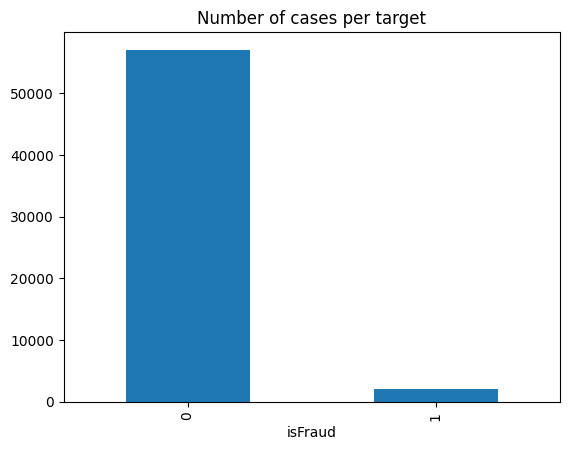

In [5]:
df['isFraud'].value_counts().plot(kind = "bar" , title = "Number of cases per target")

From the graph it is evident that there are few fradulent cases compared to the non-fradulent cases

## Handling Missing values

In [6]:
df.isnull().sum()

,0
TransactionID,0
isFraud,0
TransactionDT,0
TransactionAmt,0
ProductCD,0
...,...
id_36,44849
id_37,44849
id_38,44849
DeviceType,44869


We will now select the columns with less than 20% misssing values for imputation

In [7]:
fraud_data = df[df.columns[df.isnull().sum() < 0.2 ]]
fraud_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59054 entries, 0 to 59053
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   TransactionID   59054 non-null  int64  
 1   isFraud         59054 non-null  int64  
 2   TransactionDT   59054 non-null  int64  
 3   TransactionAmt  59054 non-null  float64
 4   ProductCD       59054 non-null  object 
 5   card1           59054 non-null  int64  
 6   C1              59054 non-null  int64  
 7   C2              59054 non-null  int64  
 8   C3              59054 non-null  int64  
 9   C4              59054 non-null  int64  
 10  C5              59054 non-null  int64  
 11  C6              59054 non-null  int64  
 12  C7              59054 non-null  int64  
 13  C8              59054 non-null  int64  
 14  C9              59054 non-null  int64  
 15  C10             59054 non-null  int64  
 16  C11             59054 non-null  int64  
 17  C12             59054 non-null 

From the information captured we see that we have now 20 columns which contain less than 20 % of missing values

### Mean Imputation

In [8]:
numeric = fraud_data.select_dtypes(include = np.number).columns
fraud_data[numeric] = fraud_data[numeric].fillna(fraud_data[numeric].mean())

<ipython-input-8-4301e948d405>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fraud_data[numeric] = fraud_data[numeric].fillna(fraud_data[numeric].mean())


### Mode Imputation

In [9]:
categorical = fraud_data.select_dtypes(include = "object").columns
fraud_data[categorical] = fraud_data[categorical].fillna(fraud_data[categorical].mode().iloc[0])

<ipython-input-9-8dac9a4101d9>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fraud_data[categorical] = fraud_data[categorical].fillna(fraud_data[categorical].mode().iloc[0])


In [10]:
fraud_data.isnull().sum().sum()

0

We now have 0 missing values in our dataset

### One  Hot Encoding

In [11]:
fraud_data = pd.get_dummies(fraud_data , columns=categorical)
fraud_data.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,card1,C1,C2,C3,C4,C5,...,C10,C11,C12,C13,C14,ProductCD_C,ProductCD_H,ProductCD_R,ProductCD_S,ProductCD_W
0,2994681,0,242834,25.000,9803,1,1,0,0,0,...,1,1,0,1,1,False,True,False,False,False
1,3557242,0,15123000,117.000,7919,1,4,0,0,0,...,0,3,0,4,1,False,False,False,False,True
2,3327470,0,8378575,73.773,12778,1,3,0,1,0,...,0,2,2,3,1,True,False,False,False,False
3,3118781,0,2607840,400.000,12316,1,1,0,1,0,...,1,1,0,1,1,False,False,True,False,False
4,3459772,0,12226544,31.950,9002,3,3,0,0,3,...,0,2,0,33,3,False,False,False,False,True


## Data Modelling

### Seperating Input variables from the output variable

In [12]:
x = fraud_data.drop("isFraud",axis = 1)
y = fraud_data["isFraud"]

### Splitting our Data into train set and test set

In [13]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y, test_size = 0.2, random_state = 42)

### Dealing with class imbalance

Since there propotionality between the fraudlent and non fradulent is not even we will under sample the majority class which is the Non-fradulent cases while we will over sample the minority class. This will help our model so that it will get more examples of the fradulent cases while also the non-fradulent

In [14]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state = 25 , sampling_strategy = 1.0)
x_train,y_train = smote.fit_resample(x_train,y_train)

## Random Forest Model

In [15]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(x_train,y_train)


RandomForestClassifier()

### Model Evaluation

In [16]:
from sklearn.metrics import accuracy_score,confusion_matrix
y_pred = rf.predict(x_test)
print("Accuracy Score : ",accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

Accuracy Score :  0.9667259334518669
[[11234   172]
 [  221   184]]


Our model has an accuracy score of 96.69% which is good though the rate of false positives and negatives are high so we can carry out hyperparameter tuning and feature selection techniques

### Feature Selection

In [17]:
from sklearn.feature_selection import RFE
rfe = RFE(rf,step=1,verbose=1)
rfe.fit(x_train,y_train)

Fitting estimator with 23 features.
Fitting estimator with 22 features.
Fitting estimator with 21 features.
Fitting estimator with 20 features.
Fitting estimator with 19 features.
Fitting estimator with 18 features.
Fitting estimator with 17 features.
Fitting estimator with 16 features.
Fitting estimator with 15 features.
Fitting estimator with 14 features.
Fitting estimator with 13 features.
Fitting estimator with 12 features.


RFE(estimator=RandomForestClassifier(), verbose=1)

In [18]:
RandomForestClassifier?

In [20]:
rfe.support_

array([ True,  True,  True,  True,  True, False, False, False,  True,
       False, False,  True,  True, False, False, False,  True,  True,
        True, False, False, False, False])

In [21]:
selected_features = pd.DataFrame({"Features":list(x_train.columns),"Ranking": rfe.ranking_})
selected_features.sort_values(by = "Ranking")

,Features,Ranking
0,TransactionID,1
1,TransactionDT,1
2,TransactionAmt,1
3,card1,1
4,C1,1
12,C9,1
11,C8,1
8,C5,1
17,C14,1
18,ProductCD_C,1


In [22]:
x_train_rfe = rfe.transform(x_train)
x_test_rfe = rfe.transform(x_test)

### Model Evaluation of the RFE model

In [23]:
rf.fit(x_train_rfe,y_train)
y_pred = rf.predict(x_test_rfe)
print("Accuracy Score : ",accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

Accuracy Score :  0.9484378968757937
[[11013   393]
 [  216   189]]


### Dimensionality Reduction using SelectKBest

In [24]:
from sklearn.feature_selection import SelectKBest, f_classif
selector = SelectKBest(f_classif,k=10)
X_new = selector.fit_transform(x,y)

In [25]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(X_new,y, random_state = 42,test_size =0.2)


In [26]:
rf.fit(x_train,y_train)
y_pred = rf.predict(x_test)
print("Accuracy Score : ",accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

Accuracy Score :  0.9714672762678859
[[11376    30]
 [  307    98]]


After using the Select KBest our model performance improved now we can now carry out HYperparamter Tuning to see if we can improve our model further

In [67]:
x_train.shape

(47243, 10)

From this we can see that reducing the features from 20 to 10 improved the model performance

## Hyper Parameter Tuning

In [68]:
RandomForestClassifier?

In [27]:
param_space = {
    'n_estimators': (10,800),
    'criterion' : ['gini','entropy'],
    'max_depth': (10,40),
    'min_samples_split':(2,10),
    'min_samples_leaf':(1,10),
    'max_features':('auto','sqrt','log2')
}


In [28]:
from sklearn.model_selection import GridSearchCV
gs = GridSearchCV(rf,param_space , cv = 5)
gs.fit(x_train,y_train)

KeyboardInterrupt: 

### Cross Validation

By doing cross-validation we mayt want to see our model behaves to unseen data,

In [29]:
from sklearn.model_selection import cross_validate
result = cross_validate(rf,x,y,cv=10,scoring = ['accuracy','recall','precision','f1'])

In [30]:
result

{'fit_time': array([8.69159007, 8.60389948, 8.58549714, 8.2711575 , 8.68072295,
        8.77117276, 8.01062369, 8.71472239, 9.61105418, 8.69138026]),
 'score_time': array([0.10801363, 0.10367393, 0.1436367 , 0.1036365 , 0.10481906,
        0.10389709, 0.10396719, 0.10322976, 0.10062242, 0.1004703 ]),
 'test_accuracy': array([0.97646461, 0.97595665, 0.97527938, 0.97527938, 0.97561389,
        0.97662997, 0.97696867, 0.97561389, 0.97544454, 0.97510584]),
 'test_recall': array([0.33830846, 0.32835821, 0.32835821, 0.32338308, 0.33      ,
        0.385     , 0.335     , 0.31      , 0.335     , 0.31840796]),
 'test_precision': array([0.91891892, 0.90410959, 0.85714286, 0.86666667, 0.86842105,
        0.83695652, 0.95714286, 0.91176471, 0.84810127, 0.86486486]),
 'test_f1': array([0.49454545, 0.48175182, 0.47482014, 0.47101449, 0.47826087,
        0.52739726, 0.4962963 , 0.46268657, 0.48028674, 0.46545455])}

In [31]:
print(f"Mean Accuracy : {result['test_accuracy'].mean()} ")
print(f"Mean Recall : {result['test_recall'].mean()} ")
print(f"Mean Precision : {result['test_precision'].mean()} ")
print(f"Mean F1 Score : {result['test_f1'].mean()} ")

Mean Accuracy : 0.9758356819640929 
Mean Recall : 0.333181592039801 
Mean Precision : 0.8834089299853108 
Mean F1 Score : 0.48325141931069543 


We can see there isn't much deviation from the baseline model hence model is ready to be deployed.

## Conclusion

We observed that the dataset contained

*   missing values. We removed some columns and filled missing values for numerical column with mean and categorical column with mode (i.e. the maximum occuring value).
*  We observed that the dataset was imblanced. We used 'SMOTE' to generate new data to deal with the problem of imbalanced data.

*  We build Random Forest model, got accuracy score of 97.53%.
*Then we selected only 10 most important features using selectKBest and f_classif. Here the model complexity is reduced a lot (which is very good) with very little decrease in accuracy
Cross Validation and Hyper parameter tunning gave nearly 96.8% of accurate results which is not bad. Most of the times the default values for hyper parameters of the models are same that we get through the hyper parameter tunning. That's the reason there is not much difference in normal model and tunned model.






